# 04 · Aprendizaje no supervisado: k-means y reducción de dimensión

**Objetivo:** implementar k-means (Lloyd + k-means++), elegir $k$ sin etiquetas, conocer sus
supuestos (clusters convexos, isotrópicos, de tamaño parecido) y combinarlo con PCA,
reutilizando la implementación del módulo de matemáticas aplicadas.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_math import pca
from applied_ml import KMeans
from sklearn import cluster
from sklearn.datasets import load_digits, make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score

## 1. Elegir k: codo e índice de silueta

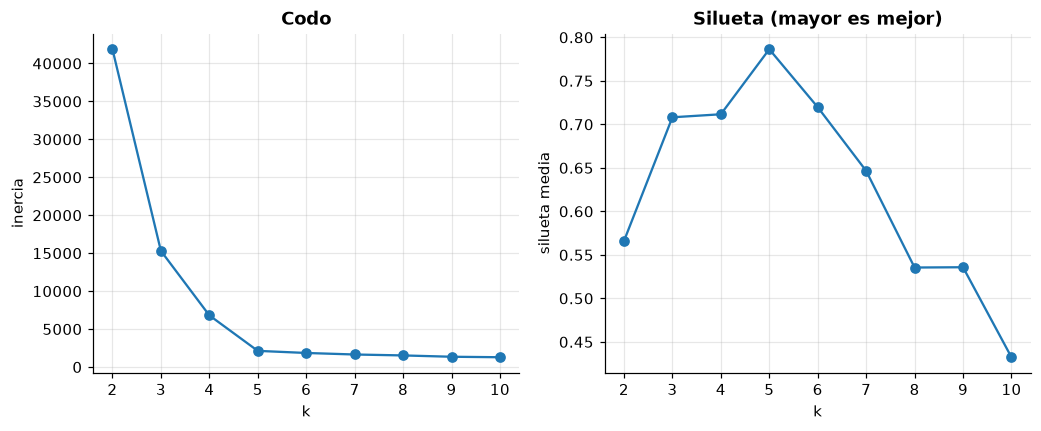

In [2]:
X, y = make_blobs(1500, centers=5, cluster_std=[0.6, 1.0, 0.8, 0.5, 1.2], random_state=7)
ks = range(2, 11)
fits = {k: KMeans(k, random_state=0).fit(X) for k in ks}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(ks), [fits[k].inertia_ for k in ks], "o-")
axes[0].set(xlabel="k", ylabel="inercia", title="Codo")
axes[1].plot(list(ks), [silhouette_score(X, fits[k].labels_) for k in ks], "o-")
axes[1].set(xlabel="k", ylabel="silueta media", title="Silueta (mayor es mejor)");

In [3]:
ours = fits[5]
ref = cluster.KMeans(5, n_init=10, random_state=0).fit(X)
print(f"inercia desde cero = {ours.inertia_:.1f} | sklearn = {ref.inertia_:.1f}")
print(f"ARI vs. etiquetas reales = {adjusted_rand_score(y, ours.labels_):.3f}")

inercia desde cero = 2130.4 | sklearn = 2130.4
ARI vs. etiquetas reales = 0.992


La inercia siempre baja al aumentar $k$ (en el límite, un cluster por punto): el “codo” es
una heurística. La silueta compara la distancia media al propio cluster con la del más cercano y
sí tiene un máximo interpretable.

## 2. Cuándo falla k-means

K-means asigna cada punto al centro más cercano: las fronteras son hiperplanos (celdas de Voronoi).
No puede separar formas no convexas ni clusters alargados.

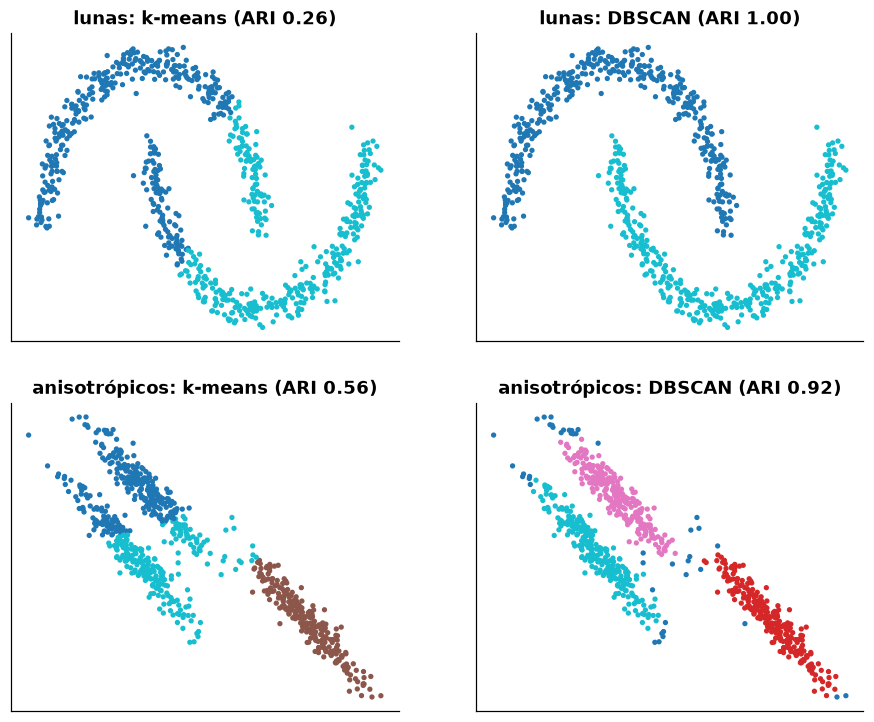

In [4]:
moons, ym = make_moons(800, noise=0.06, random_state=0)
aniso, ya = make_blobs(800, centers=3, random_state=170)
aniso = aniso @ np.array([[0.6, -0.64], [-0.4, 0.85]])
cases = {"lunas": (moons, ym, 2, 0.2), "anisotrópicos": (aniso, ya, 3, 0.35)}
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (name, (Xc, yc, k, eps)) in enumerate(cases.items()):
    km = KMeans(k, random_state=0).fit(Xc).labels_
    db = cluster.DBSCAN(eps=eps, min_samples=10).fit_predict(Xc)
    for ax, labels, title in [(axes[row, 0], km, "k-means"), (axes[row, 1], db, "DBSCAN")]:
        ax.scatter(*Xc.T, c=labels, s=6, cmap="tab10")
        ax.set_title(f"{name}: {title} (ARI {adjusted_rand_score(yc, labels):.2f})")
        ax.set_xticks([])
        ax.set_yticks([])

DBSCAN (de la librería) agrupa por densidad y no asume formas: resuelve las lunas, pero
necesita elegir `eps` y sufre cuando las densidades difieren.

## 3. Dígitos: PCA + k-means

1797 imágenes de 8×8 = 64 dimensiones. PCA (desde cero, módulo 01) para visualizar;
k-means con $k = 10$ en el espacio completo, comparado con las etiquetas reales.

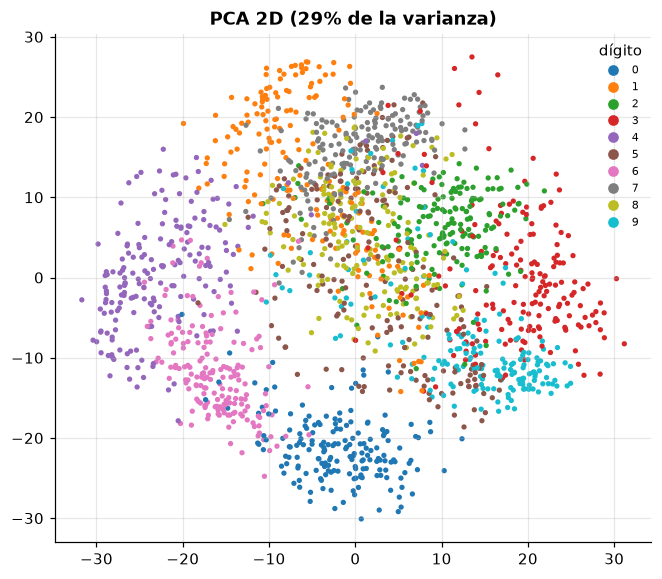

In [5]:
digits = load_digits()
Xd, yd = digits.data, digits.target
proj, comps, var = pca(Xd, 2)
total_var = np.var(Xd - Xd.mean(0), axis=0, ddof=1).sum()
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(*proj.T, c=yd, cmap="tab10", s=6)
ax.legend(*sc.legend_elements(), title="dígito", fontsize=7, loc="upper right")
ax.set_title(f"PCA 2D ({var.sum() / total_var:.0%} de la varianza)");

In [6]:
km = KMeans(10, random_state=0).fit(Xd)
print(f"ARI k-means (64 dim) = {adjusted_rand_score(yd, km.labels_):.3f}")
for d in [2, 10, 30]:
    p, _, _ = pca(Xd, d)
    labels = KMeans(10, random_state=0).fit(p).labels_
    print(f"ARI k-means sobre PCA({d:>2}) = {adjusted_rand_score(yd, labels):.3f}")

ARI k-means (64 dim) = 0.663
ARI k-means sobre PCA( 2) = 0.392
ARI k-means sobre PCA(10) = 0.652
ARI k-means sobre PCA(30) = 0.669


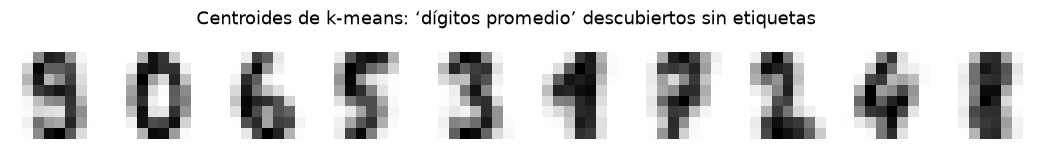

In [7]:
fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, center in zip(axes, km.cluster_centers_, strict=True):
    ax.imshow(center.reshape(8, 8), cmap="gray_r")
    ax.axis("off")
fig.suptitle("Centroides de k-means: ‘dígitos promedio’ descubiertos sin etiquetas");

## Para llevar

- K-means minimiza la inercia con óptimos locales: k-means++ y varios reinicios son obligatorios.
- Elegir $k$ con silueta (o con el uso posterior), no solo con el codo.
- Supuestos fuertes: clusters convexos e isotrópicos. Si no se cumplen, densidad (DBSCAN) o mezclas.
- PCA antes de agrupar quita ruido y acelera; con pocas componentes, puede borrar estructura útil.